# Frecuencias naturales del puente openBridgeLAB: estado de referencia

Este notebook calcula las frecuencias naturales del puente openBridgeLAB (Bautzen) en cada una de las 56 mediciones del estado de referencia (29 y 30 de abril de 2025). Las frecuencias se identifican a partir de las aceleraciones medidas bajo excitación ambiental, con el método de descomposición en el dominio de la frecuencia (FDD, *Frequency Domain Decomposition*).

## 1. Configuración

Se cargan las librerías y se definen los parámetros del cálculo:

- **Diezmado:** las señales vienen a 1000 Hz, pero los modos del puente están por debajo de unos 40 Hz. Por eso se diezman por 10, a 100 Hz (frecuencia de Nyquist de 50 Hz), lo que reduce mucho el tiempo de cálculo.
- **Segmentos de Welch:** de 4096 muestras (40,96 s) con 50 % de solapamiento. La resolución en frecuencia es $\Delta f = 100/4096 \approx 0{,}024$ Hz y cada registro de 600 s da 28 segmentos para promediar.
- **Canal excluido:** el canal 12 (posición 8), porque la hoja de datos advierte que puede dar datos poco fiables, sobre todo de noche.
- **Banda de búsqueda:** de 2 a 40 Hz. Por debajo de 2 Hz el espectro está dominado por ruido común a todos los canales, y por encima de 40 Hz los picos no se repiten de un registro a otro (además está la interferencia eléctrica de 50 Hz).

In [1]:
from pathlib import Path

import h5py
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import signal

DATA_DIR = Path("data_upload") / "Reference_State"
RESULTS_DIR = Path("results")

FS = 1000.0                 # sampling frequency of the files (Hz)
DECIMATION = 10             # decimation factor
FS_DEC = FS / DECIMATION    # sampling frequency after decimation (Hz)
NPERSEG = 4096              # samples per Welch segment
N_CHANNELS = 32
EXCLUDED_CHANNELS = [12]    # unreliable channel according to the data sheet

F_MIN, F_MAX = 2.0, 40.0    # frequency band where modes are searched (Hz)
PROMINENCE_DB = 3.0         # minimum prominence of a candidate peak (dB)
SEARCH_WINDOW = 0.03        # half-width of the search window, relative to the reference frequency
MAC_MIN = 0.9               # minimum MAC between the record and the reference mode shape
MIN_DETECTION = 0.9         # minimum fraction of records where a mode must be found

CHANNELS = [ch for ch in range(1, N_CHANNELS + 1) if ch not in EXCLUDED_CHANNELS]

# To number the tables and figures automatically
t_num = 0
f_num = 0

# Function to display a DataFrame as a table with a caption and optional formatting
def show_table(df, number, caption, precision=2, hide_index=False, n_rows=None):
    display(Markdown(f"**Tabla {number}.** {caption}"))

    # Truncate table (for long DataFrames)
    if n_rows is not None and len(df) > 2 * n_rows:
        ellipsis_row = pd.DataFrame([["..."] * df.shape[1]], columns=df.columns, index=["..."])
        df = pd.concat([df.head(n_rows), ellipsis_row, df.tail(n_rows)])

    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)

# Function to display a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

## 2. Mediciones

Cada archivo `.h5` contiene el dataset `RecBuff`, de 33 filas: la fila 0 es el tiempo en µs y las filas 1 a 32 son las aceleraciones de los canales 1 a 32, en m/s². La fecha y hora de inicio de cada medición se lee del atributo `Datum`.

In [2]:
files = sorted(DATA_DIR.glob("*/*.h5"))

records = []
for path in files:
    with h5py.File(path, "r") as h5:
        dataset = h5["RecBuff"]
        records.append({
            "start": pd.to_datetime(dataset.attrs["Datum"], format="%d-%b-%Y %H:%M:%S"),
            "file": path.name,
            "duration_s": float(dataset.attrs["Messdauer"][0]),
            "fs_hz": float(dataset.attrs["Sampletime"][0]),
            "shape": dataset.shape,
        })
records = pd.DataFrame(records)

t_num += 1
show_table(records, t_num, "Mediciones del estado de referencia.", n_rows=5)
print(f"{len(records)} measurements: {(records['start'].dt.date == records['start'].dt.date.iloc[0]).sum()} on "
      f"{records['start'].dt.date.iloc[0]} and {(records['start'].dt.date != records['start'].dt.date.iloc[0]).sum()} "
      f"on {records['start'].dt.date.iloc[-1]}")

**Tabla 1.** Mediciones del estado de referencia.

,start,file,duration_s,fs_hz,shape
0,2025-04-29 15:56:40,2025-04-29_Messung_Bautzen_1556.h5,600.00,1000.00,"(33, 600000)"
1,2025-04-29 20:23:35,2025-04-29_Messung_Bautzen_2023.h5,600.00,1000.00,"(33, 600000)"
2,2025-04-29 21:25:43,2025-04-29_Messung_Bautzen_2125.h5,600.00,1000.00,"(33, 600000)"
3,2025-04-29 21:36:04,2025-04-29_Messung_Bautzen_2136.h5,600.00,1000.00,"(33, 600000)"
4,2025-04-29 22:07:07,2025-04-29_Messung_Bautzen_2207.h5,600.00,1000.00,"(33, 600000)"
...,...,...,...,...,...
51,2025-04-30 11:05:13,2025-04-30_Messung_Bautzen_1105.h5,600.00,1000.00,"(33, 600000)"
52,2025-04-30 11:25:56,2025-04-30_Messung_Bautzen_1125.h5,600.00,1000.00,"(33, 600000)"
53,2025-04-30 11:36:17,2025-04-30_Messung_Bautzen_1136.h5,600.00,1000.00,"(33, 600000)"
54,2025-04-30 11:46:38,2025-04-30_Messung_Bautzen_1146.h5,600.00,1000.00,"(33, 600000)"


56 measurements: 14 on 2025-04-29 and 42 on 2025-04-30


## 3. Método: descomposición en el dominio de la frecuencia (FDD)

Bajo excitación ambiental no se conoce la fuerza que actúa sobre el puente, solo su respuesta. El método FDD supone que esa excitación es aproximadamente ruido blanco, de modo que los picos del espectro de la respuesta corresponden a los modos de la estructura.

**Matriz de densidades espectrales.** Para cada medición se divide la señal de cada canal en $n_s$ segmentos, se aplica una ventana de Hann y se calcula la transformada de Fourier de cada segmento. Con ellas se estima la matriz de densidades espectrales cruzadas:

$$
\hat{\mathbf{G}}_{yy}(f_k) = \frac{1}{n_s} \sum_{s=1}^{n_s} \mathbf{Y}_s(f_k)\, \mathbf{Y}_s(f_k)^H
\tag{1}
$$

donde $\mathbf{Y}_s(f_k)$ es el vector con la transformada de Fourier de los $n_c = 31$ canales en el segmento $s$ y la frecuencia $f_k$, el superíndice $H$ indica la traspuesta conjugada y $\hat{\mathbf{G}}_{yy}(f_k)$ es una matriz hermítica de $n_c \times n_c$. El término diagonal $(i,i)$ es la densidad espectral de potencia del canal $i$ y el término $(i,j)$ es la densidad espectral cruzada entre los canales $i$ y $j$. Se omite el factor de escala de la densidad espectral, porque solo interesa la posición de los picos.

**Descomposición en valores singulares.** En cada frecuencia, la matriz se descompone como:

$$
\hat{\mathbf{G}}_{yy}(f_k) = \mathbf{U}_k\, \mathbf{S}_k\, \mathbf{U}_k^H
\tag{2}
$$

donde $\mathbf{S}_k = \mathrm{diag}(s_1, s_2, \dots, s_{n_c})$ contiene los valores singulares ordenados de mayor a menor y las columnas de $\mathbf{U}_k = [\mathbf{u}_1, \mathbf{u}_2, \dots]$ son los vectores singulares. Cerca de una frecuencia natural domina un solo modo, de modo que el primer valor singular $s_1(f)$ presenta un pico y el vector $\mathbf{u}_1$ es una estimación de la forma modal $\boldsymbol{\phi}$ en los sensores.

**Criterio MAC.** Para comprobar que un pico de una medición corresponde al mismo modo que en las demás, se compara su vector $\mathbf{u}_1$ con la forma modal de referencia $\boldsymbol{\phi}_{\mathrm{ref}}$ mediante el *Modal Assurance Criterion*:

$$
\mathrm{MAC}(\boldsymbol{\phi}_a, \boldsymbol{\phi}_b) = \frac{\left|\boldsymbol{\phi}_a^H \boldsymbol{\phi}_b\right|^2}{\left(\boldsymbol{\phi}_a^H \boldsymbol{\phi}_a\right)\left(\boldsymbol{\phi}_b^H \boldsymbol{\phi}_b\right)}
\tag{3}
$$

donde $\boldsymbol{\phi}_a$ y $\boldsymbol{\phi}_b$ son las dos formas modales comparadas. El MAC vale 1 si las formas son proporcionales y 0 si son ortogonales.

**Interpolación del pico.** La frecuencia del pico se afina por debajo de la resolución $\Delta f$ ajustando una parábola a $y = \ln s_1$ en el máximo $k$ y sus dos vecinos:

$$
\hat{f} = f_k + \frac{1}{2}\,\frac{y_{k-1} - y_{k+1}}{y_{k-1} - 2y_k + y_{k+1}}\,\Delta f
\tag{4}
$$

donde $f_k$ es la frecuencia de la línea espectral con el máximo, $y_{k-1}$, $y_k$ e $y_{k+1}$ son los valores de $\ln s_1$ en esa línea y sus vecinas, y $\hat{f}$ es la frecuencia estimada del modo.

In [3]:
# Cross spectral density matrix (Eq. 1) and its singular value decomposition (Eq. 2)
def fdd(acc):
    acc_dec = signal.decimate(acc, DECIMATION, ftype="fir", zero_phase=True, axis=1)
    f, _, Y = signal.stft(acc_dec, fs=FS_DEC, window="hann", nperseg=NPERSEG, noverlap=NPERSEG // 2,
                          detrend="constant", boundary=None, padded=False)
    G = np.einsum("ifs,jfs->fij", Y, Y.conj()) / Y.shape[2]
    U, s, _ = np.linalg.svd(G)
    return f, G, s, U[:, :, 0]

# Modal Assurance Criterion (Eq. 3); phi_a can hold several vectors, one per row
def mac(phi_a, phi_b):
    return np.abs(phi_a @ phi_b.conj()) ** 2 / (np.sum(np.abs(phi_a) ** 2, axis=-1) * np.sum(np.abs(phi_b) ** 2))

# Peak frequency refined with a parabola through ln(s1) (Eq. 4)
def refine_peak(f, s1, k):
    y0, y1, y2 = np.log(s1[k - 1:k + 2])
    return f[k] + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2) * (f[1] - f[0])

## 4. Matriz espectral de cada medición

Se aplica la Ec. (2) a las 56 mediciones. De cada una se guardan los tres primeros valores singulares y el primer vector singular en cada frecuencia.

Además se acumula una matriz espectral promedio de todas las mediciones, que servirá de referencia en la sección 5. Antes de sumarla, la matriz de cada medición se divide por su traza media. Así, las mediciones nocturnas, que tienen entre 100 y 400 veces menos energía que las diurnas, pesan lo mismo que las diurnas en el promedio.

Este paso tarda unos tres minutos.

In [4]:
s_all, u1_all = [], []
G_ref = 0
for path in files:
    with h5py.File(path, "r") as h5:
        acc = h5["RecBuff"][1:][[ch - 1 for ch in CHANNELS]]
    f, G, s, u1 = fdd(acc)
    s_all.append(s[:, :3])
    u1_all.append(u1)
    G_ref = G_ref + G / np.trace(G, axis1=1, axis2=2).real.mean()

s_all = np.array(s_all)    # (record, frequency, singular value)
u1_all = np.array(u1_all)  # (record, frequency, channel)
G_ref = G_ref / len(files)
print(f"Frequency resolution: {f[1]:.4f} Hz, {len(f)} frequency lines, {len(CHANNELS)} channels")

Frequency resolution: 0.0244 Hz, 2049 frequency lines, 31 channels


## 5. Modos de referencia y seguimiento en cada medición

La identificación se hace en dos pasos:

1. **Modos candidatos.** Se calcula la SVD de la matriz espectral promedio y se buscan los picos de su primer valor singular entre 2 y 40 Hz con una prominencia de al menos 3 dB. Cada pico da una frecuencia de referencia $f_{\mathrm{ref}}$ y una forma modal de referencia $\boldsymbol{\phi}_{\mathrm{ref}}$.
2. **Seguimiento.** En cada medición se busca el modo dentro de una ventana de $\pm 3\,\%$ alrededor de $f_{\mathrm{ref}}$. Solo se consideran las frecuencias cuyo vector $\mathbf{u}_1$ tiene un MAC de al menos 0,9 con $\boldsymbol{\phi}_{\mathrm{ref}}$ (Ec. 3); de ellas se toma la de mayor $s_1$ y se afina con la Ec. (4). Si no hay ninguna, o si el máximo cae en el borde de la ventana (no es un pico), el modo se da por no encontrado en esa medición.

Se conservan los modos encontrados en al menos el 90 % de las mediciones (51 de 56). Los demás se descartan: son modos débiles que solo se excitan en algunos registros o picos que no corresponden siempre a la misma forma modal.

In [5]:
# Step 1: candidate modes from the averaged spectral matrix
U_ref, s_ref, _ = np.linalg.svd(G_ref)
s1_ref_db = 10 * np.log10(s_ref[:, 0])
in_band = (f >= F_MIN) & (f <= F_MAX)
band_idx = np.flatnonzero(in_band)
peaks, peak_props = signal.find_peaks(s1_ref_db[band_idx], prominence=PROMINENCE_DB)
peaks = band_idx[peaks]

# Step 2: track each candidate in every record
def track_mode(k_ref):
    f_ref, phi_ref = f[k_ref], U_ref[k_ref, :, 0]
    window = np.flatnonzero(np.abs(f - f_ref) <= SEARCH_WINDOW * f_ref)
    freqs = np.full(len(files), np.nan)
    macs = np.full(len(files), np.nan)
    for r in range(len(files)):
        mac_w = mac(u1_all[r, window], phi_ref)
        s1_w = s_all[r, window, 0]
        if not (mac_w >= MAC_MIN).any():
            continue
        i = np.argmax(np.where(mac_w >= MAC_MIN, s1_w, 0))
        if i in (0, len(window) - 1):
            continue
        freqs[r] = refine_peak(f, s_all[r, :, 0], window[i])
        macs[r] = mac_w[i]
    return freqs, macs

tracked = [track_mode(k) for k in peaks]
candidates = pd.DataFrame({
    "f_ref (Hz)": f[peaks],
    "prominence (dB)": peak_props["prominences"],
    "found": [np.isfinite(fr).sum() for fr, _ in tracked],
    "found (%)": [100 * np.isfinite(fr).mean() for fr, _ in tracked],
    "median MAC": [np.nanmedian(m) if np.isfinite(m).any() else np.nan for _, m in tracked],
})
candidates["kept"] = np.where(candidates["found (%)"] >= 100 * MIN_DETECTION, "yes", "no")

t_num += 1
show_table(candidates, t_num, "Modos candidatos del espectro promedio y número de mediciones en que se encontraron.",
           precision=3, hide_index=True)

**Tabla 2.** Modos candidatos del espectro promedio y número de mediciones en que se encontraron.

f_ref (Hz),prominence (dB),found,found (%),median MAC,kept
4.663,19.303,55,98.214,0.994,yes
5.347,4.614,33,58.929,0.951,no
6.079,4.465,45,80.357,0.990,no
7.251,19.869,54,96.429,0.998,yes
8.911,15.607,55,98.214,0.997,yes
10.742,15.009,55,98.214,0.960,yes
16.626,22.927,54,96.429,0.976,yes
19.409,3.214,12,21.429,0.923,no
21.948,7.789,45,80.357,0.936,no
25.342,11.899,56,100.000,0.984,yes


La Figura 1 muestra el espectro de referencia con los modos candidatos y el primer valor singular de cada una de las 56 mediciones.

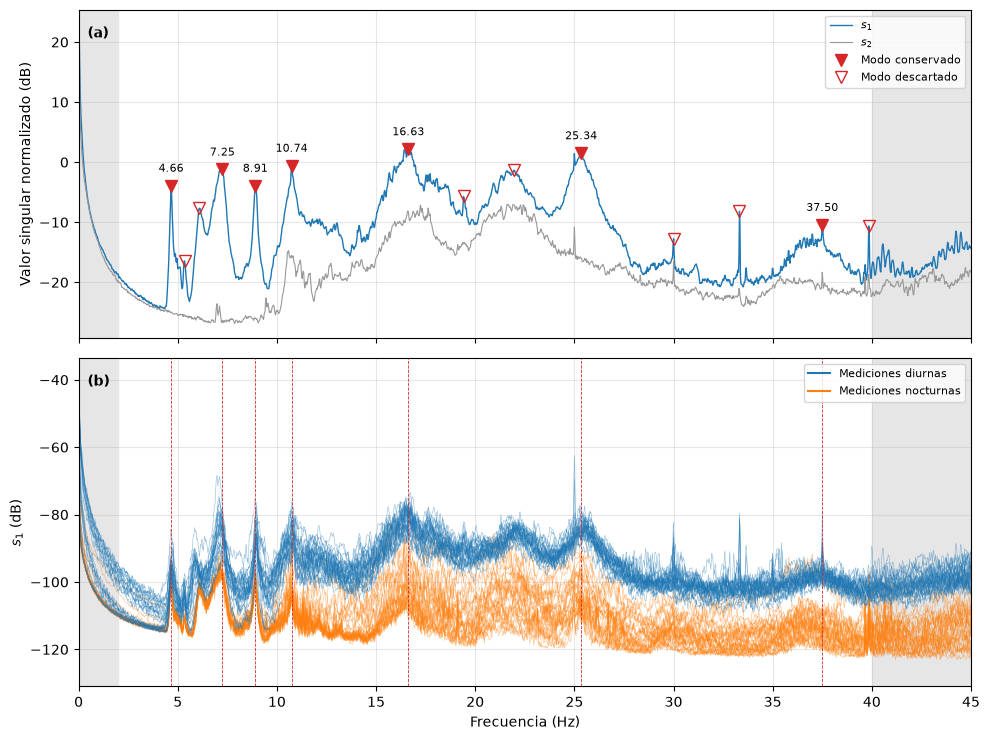

**Figura 1.** Primer valor singular de la matriz espectral. (a) Espectro promedio de las 56 mediciones, normalizado por medición, con los modos candidatos: los triángulos rellenos son los modos conservados y los vacíos, los descartados. (b) Primer valor singular de cada medición; las líneas discontinuas marcan los modos conservados. Las bandas grises quedan fuera del rango de búsqueda (2 a 40 Hz).

In [6]:
kept = candidates["kept"].eq("yes").to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True)

ax = axes[0]
ax.plot(f, s1_ref_db, color="C0", lw=1, label="$s_1$")
ax.plot(f, 10 * np.log10(s_ref[:, 1]), color="0.6", lw=0.8, label="$s_2$")
ax.plot(f[peaks[kept]], s1_ref_db[peaks[kept]], "v", color="C3", ms=8, label="Modo conservado")
ax.plot(f[peaks[~kept]], s1_ref_db[peaks[~kept]], "v", mfc="none", color="C3", ms=8, label="Modo descartado")
for k in peaks[kept]:
    ax.annotate(f"{f[k]:.2f}", (f[k], s1_ref_db[k]), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
ax.set_ylabel("Valor singular normalizado (dB)")
ax.legend(loc="upper right", fontsize=8)
ax.text(0.01, 0.95, "(a)", transform=ax.transAxes, va="top", fontweight="bold")

ax = axes[1]
is_night = (records["start"].dt.hour >= 20) | (records["start"].dt.hour < 5)
for r in range(len(files)):
    ax.plot(f, 10 * np.log10(s_all[r, :, 0]), lw=0.4, alpha=0.5, color="C1" if is_night[r] else "C0")
ax.plot([], [], color="C0", label="Mediciones diurnas")
ax.plot([], [], color="C1", label="Mediciones nocturnas")
for k in peaks[kept]:
    ax.axvline(f[k], color="C3", lw=0.6, ls="--")
ax.set_ylabel(r"$s_1$ (dB)")
ax.set_xlabel("Frecuencia (Hz)")
ax.legend(loc="upper right", fontsize=8)
ax.text(0.01, 0.95, "(b)", transform=ax.transAxes, va="top", fontweight="bold")

for ax in axes:
    ax.set_xlim(0, 45)
    ax.axvspan(0, F_MIN, color="0.9")
    ax.axvspan(F_MAX, 45, color="0.9")
    ax.grid(alpha=0.3)
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Primer valor singular de la matriz espectral. (a) Espectro promedio de las 56 mediciones, "
            "normalizado por medición, con los modos candidatos: los triángulos rellenos son los modos conservados y "
            "los vacíos, los descartados. (b) Primer valor singular de cada medición; las líneas discontinuas marcan "
            "los modos conservados. Las bandas grises quedan fuera del rango de búsqueda (2 a 40 Hz).")

## 6. Frecuencias naturales de cada medición

La Tabla 3 reúne las frecuencias de los modos conservados en las 56 mediciones. Las celdas vacías (`NaN`) corresponden a mediciones en las que el modo no cumplió los criterios de la sección 5. La tabla se guarda también en `results/natural_frequencies_reference_state.csv`.

In [7]:
mode_names = [f"f{i} (Hz)" for i in range(1, kept.sum() + 1)]
frequencies = pd.DataFrame(np.column_stack([tracked[i][0] for i in np.flatnonzero(kept)]), columns=mode_names)
frequencies.insert(0, "start", records["start"])
frequencies.insert(1, "file", records["file"])

RESULTS_DIR.mkdir(exist_ok=True)
frequencies.to_csv(RESULTS_DIR / "natural_frequencies_reference_state.csv", index=False)

t_num += 1
show_table(frequencies, t_num, "Frecuencias naturales identificadas en cada medición del estado de referencia.",
           precision=3)

**Tabla 3.** Frecuencias naturales identificadas en cada medición del estado de referencia.

,start,file,f1 (Hz),f2 (Hz),f3 (Hz),f4 (Hz),f5 (Hz),f6 (Hz),f7 (Hz)
0,2025-04-29 15:56:40,2025-04-29_Messung_Bautzen_1556.h5,nan,7.103,nan,nan,nan,25.340,36.574
1,2025-04-29 20:23:35,2025-04-29_Messung_Bautzen_2023.h5,4.643,7.089,8.865,10.782,16.268,25.265,36.808
2,2025-04-29 21:25:43,2025-04-29_Messung_Bautzen_2125.h5,4.646,7.129,8.892,10.645,16.373,25.280,37.109
3,2025-04-29 21:36:04,2025-04-29_Messung_Bautzen_2136.h5,4.656,7.165,8.884,10.688,16.263,25.133,37.000
4,2025-04-29 22:07:07,2025-04-29_Messung_Bautzen_2207.h5,4.654,7.133,8.904,10.675,16.496,25.235,36.397
5,2025-04-29 22:17:28,2025-04-29_Messung_Bautzen_2217.h5,4.656,7.183,8.891,10.656,nan,25.196,36.412
6,2025-04-29 22:27:49,2025-04-29_Messung_Bautzen_2227.h5,4.657,7.099,8.905,10.693,16.476,25.266,36.794
7,2025-04-29 22:38:11,2025-04-29_Messung_Bautzen_2238.h5,4.656,7.104,8.904,10.670,16.603,25.125,36.590
8,2025-04-29 22:48:32,2025-04-29_Messung_Bautzen_2248.h5,4.657,7.087,8.908,10.677,16.514,25.225,37.266
9,2025-04-29 22:58:53,2025-04-29_Messung_Bautzen_2258.h5,4.664,7.091,8.897,10.666,16.603,24.989,36.880


In [8]:
summary = pd.DataFrame({
    "mode": range(1, kept.sum() + 1),
    "f_ref (Hz)": f[peaks[kept]],
    "found": frequencies[mode_names].notna().sum().to_numpy(),
    "mean (Hz)": frequencies[mode_names].mean().to_numpy(),
    "std (Hz)": frequencies[mode_names].std().to_numpy(),
    "min (Hz)": frequencies[mode_names].min().to_numpy(),
    "max (Hz)": frequencies[mode_names].max().to_numpy(),
})
summary["CV (%)"] = 100 * summary["std (Hz)"] / summary["mean (Hz)"]

t_num += 1
show_table(summary, t_num, "Resumen de las frecuencias naturales en las 56 mediciones del estado de referencia "
           "(CV: coeficiente de variación).", precision=3, hide_index=True)

**Tabla 4.** Resumen de las frecuencias naturales en las 56 mediciones del estado de referencia (CV: coeficiente de variación).

mode,f_ref (Hz),found,mean (Hz),std (Hz),min (Hz),max (Hz),CV (%)
1,4.663,55,4.673,0.027,4.576,4.751,0.569
2,7.251,54,7.178,0.076,7.079,7.395,1.064
3,8.911,55,8.929,0.029,8.865,8.988,0.329
4,10.742,55,10.734,0.062,10.476,10.868,0.578
5,16.626,54,16.567,0.152,16.238,17.060,0.920
6,25.342,56,25.367,0.228,24.761,25.954,0.898
7,37.500,51,37.156,0.479,36.397,38.103,1.288


La Figura 2 muestra cómo varía cada frecuencia a lo largo de las aproximadamente 20 horas de medición.

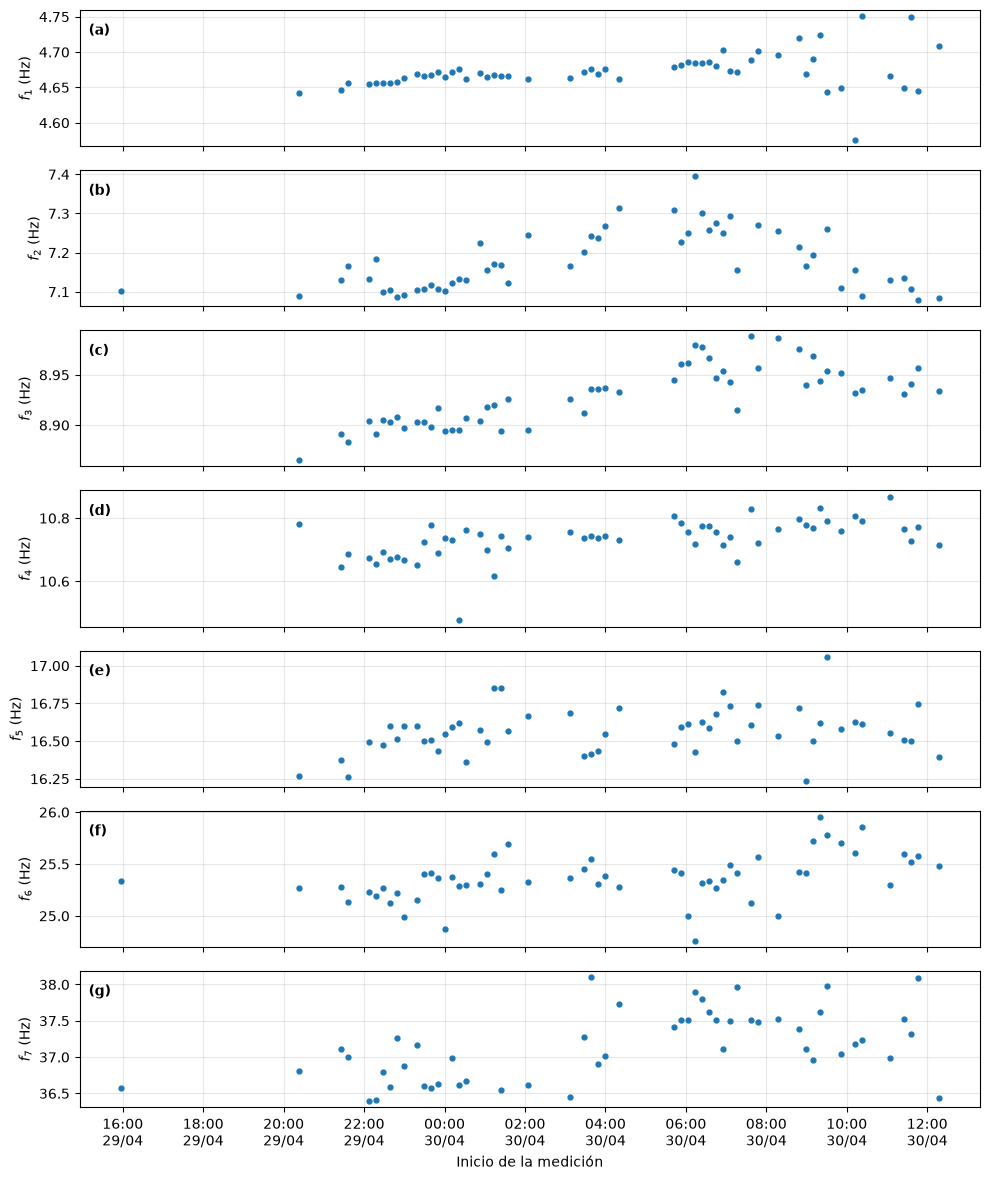

**Figura 2.** Frecuencias naturales identificadas en cada medición del estado de referencia, del 29 de abril (15:56) al 30 de abril de 2025 (12:17). Cada panel, de (a) a (g), corresponde a un modo, de menor a mayor frecuencia.

In [9]:
n_modes = len(mode_names)
fig, axes = plt.subplots(n_modes, 1, figsize=(10, 1.7 * n_modes), sharex=True)
for i, (ax, name) in enumerate(zip(axes, mode_names)):
    ax.plot(frequencies["start"], frequencies[name], "o", ms=3.5, color="C0")
    ax.set_ylabel(f"$f_{i + 1}$ (Hz)")
    ax.grid(alpha=0.3)
    ax.text(0.01, 0.9, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].xaxis.set_major_locator(mdates.HourLocator(interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%d/%m"))
axes[-1].set_xlabel("Inicio de la medición")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Frecuencias naturales identificadas en cada medición del estado de referencia, del 29 de abril "
            "(15:56) al 30 de abril de 2025 (12:17). Cada panel, de (a) a "
            f"({chr(96 + n_modes)}), corresponde a un modo, de menor a mayor frecuencia.")

## 7. Observaciones

- Se identificaron siete modos entre 4,67 y 37,2 Hz que aparecen en al menos 51 de las 56 mediciones (Tabla 4). Los demás picos del espectro se descartaron (Tabla 2): unos son modos débiles que solo se ven en algunos registros (5,35, 6,08 y 21,95 Hz) y otros son picos muy estrechos que no se repiten (30,0, 33,3 y 39,8 Hz), probablemente ruido de origen mecánico o eléctrico.
- Los modos 1, 3 y 4 (4,67, 8,93 y 10,73 Hz) son los más estables, con un coeficiente de variación menor que 0,6 %. Sus picos son estrechos y bien separados (Figura 1).
- Los modos 2 y 3 aumentan durante la noche y la madrugada y vuelven a bajar a media mañana (Figura 2b y c). Esa tendencia coincide con el enfriamiento y posterior calentamiento del aire, lo que sugiere un efecto de la temperatura que habrá que estudiar aparte.
- Los modos 5, 6 y 7 tienen más dispersión, porque sus picos son anchos (Figura 1a). El modo 7 corresponde a una zona ancha del espectro, de 35 a 39 Hz, y sus valores se agrupan en dos niveles, unos 36,6 Hz de noche y 37,5 Hz de día (Figura 2g). Podría tratarse de dos modos cercanos, así que conviene tomarlo con cautela.
- En la primera medición (15:56 del 29 de abril) solo se encontraron los modos 2, 6 y 7. Según la hoja de datos, la campaña empezó a las 20:15, así que puede tratarse de una medición de prueba.